# Few-shot Universal Dependency parsing with LLMs

Baseline experiment for the multilingual UD parsing project: how much dependency-parsing ability does a pretrained LLM have **without weight updates**, given $N \in \{0,3,5,10\}$ demonstrations in the prompt?

**Pipeline**
1. Load UD treebanks (demo pool from train, else dev, else held-out part of test).
2. Linearize trees into the U-DepPLLaMA bracketed format, e.g. `[ROOT[NSUBJ[He]][AUX[was]][recognized]...]`.
3. Build completion-style prompts (identical instruction, only demonstrations vary; demonstrations are nested across $N$ and shared across models).
4. Greedy decoding with a 4-bit quantized model.
5. Parse the output back to heads and relations; recover as in the paper (reorder, attach missing words to root); invalid output counts as all wrong.
6. Score UAS, LAS, F1, invalid-output rate; aggregate over seeds; rank models.

**Metrics.** With $n_{\text{gold}}$ gold words, $n_{\text{sys}}$ system words, and $c_{\text{head}}$, $c_{\text{las}}$ the number of words with correct head, or correct head and label:

$$\mathrm{UAS}=\frac{c_{\text{head}}}{n_{\text{gold}}},\qquad \mathrm{LAS}=\frac{c_{\text{las}}}{n_{\text{gold}}},\qquad P=\frac{c_{\text{las}}}{n_{\text{sys}}},\; R=\frac{c_{\text{las}}}{n_{\text{gold}}},\; F_1=\frac{2PR}{P+R}$$

Scores are micro-averaged over words. Label comparison ignores UD subtypes (`nsubj:pass` $\to$ `nsubj`), as in the CoNLL shared-task LAS.

## 1. Setup

In [ ]:
!pip install -q conllu "transformers>=4.44" accelerate bitsandbytes pandas matplotlib

In [ ]:
import os, re, json, random, math, glob, time, urllib.request
from collections import Counter, defaultdict
import numpy as np, pandas as pd, torch, conllu

# ---------------- CONFIG ----------------
CFG = dict(
    # name -> HF id. VERIFY ids/access (Llama-2 and Aya are gated: accept the license and set HF_TOKEN).
    models = {
        "Qwen3.5-9B":      "Qwen/Qwen3.5-9B-Base",
        "llama-3.1":       "meta-llama/Llama-3.1-8B",
        "aya-expanse-8b": "CohereLabs/aya-expanse-8b",
        "bolmo-7b":       "allenai/Bolmo-7B",
    },
    run_models   = ["llama-3.1"],            # start with one; add the others later
    treebanks    = ["en_ewt", "en_gum", "de_gsd", "de_hdt", "af_afribooms",
                    "fo_farpahc", "fo_oft", "bar_maibaam", "hy_armtdp"],
    shots        = [0, 3, 5, 10],
    seeds        = [0, 1, 2],                # demonstration seeds (0-shot is run once)
    mode         = "gold",                   # "gold": gold tokenization | "raw": raw text input
    n_eval       = 200,                      # eval sentences per treebank (fixed random subset)
    max_eval_words = 40,
    max_demo_words = 25,
    batch_size   = 8,
    demo_source  = {},                       # ablation, e.g. {"bar_maibaam": "de_gsd"} = German demos for Bavarian
    held_out_demos = 50,                     # demo pool size carved from test when a treebank has no train/dev
    strip_subtypes = True,
    out_dir      = "/content/drive/MyDrive/fewshot_ud",    # set to a Drive path to survive disconnects
)
# resource level (used for weighting in the final ranking)
LEVEL = dict(en_ewt="HR", en_gum="HR", de_gsd="HR", de_hdt="HR",
             af_afribooms="MR", hy_armtdp="MR", fo_farpahc="LR", fo_oft="LR", bar_maibaam="LR")
WEIGHT = dict(HR=1.0, MR=1.5, LR=2.0)

# (repo, file prefix)
TREEBANKS = {
    "en_ewt":       ("UD_English-EWT", "en_ewt"),
    "en_gum":       ("UD_English-GUM", "en_gum"),
    "de_gsd":       ("UD_German-GSD", "de_gsd"),
    "de_hdt":       ("UD_German-HDT", "de_hdt"),
    "af_afribooms": ("UD_Afrikaans-AfriBooms", "af_afribooms"),
    "fo_farpahc":   ("UD_Faroese-FarPaHC", "fo_farpahc"),
    "fo_oft":       ("UD_Faroese-OFT", "fo_oft"),
    "bar_maibaam":  ("UD_Bavarian-MaiBaam", "bar_maibaam"),
    "hy_armtdp":    ("UD_Armenian-ArmTDP", "hy_armtdp"),
}
DATA_DIR = "/content/ud_data"
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(CFG["out_dir"], exist_ok=True)

In [ ]:
# Optional: HF login for gated models (Colab: add HF_TOKEN under Secrets)
import os
from google.colab import drive

if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive', force_remount=True)
else:
    print("Google Drive is already mounted.")

os.environ["HF_HOME"] = "/content/drive/MyDrive/hf_cache"

try:
    from google.colab import userdata
    from huggingface_hub import login
    login(userdata.get("HF_TOKEN"))
except Exception as e:
    print("No HF login:", e)

Google Drive is already mounted.


## 2. Data

In [ ]:
def fetch(repo, prefix, split):
    path = f"{DATA_DIR}/{prefix}-ud-{split}.conllu"
    if not (os.path.exists(path) and os.path.getsize(path) > 0):
        url = f"https://raw.githubusercontent.com/UniversalDependencies/{repo}/master/{prefix}-ud-{split}.conllu"
        try: urllib.request.urlretrieve(url, path)
        except Exception:
            if os.path.exists(path): os.remove(path)
            return None
    return path

def clean(form):
    # brackets would break the tree format; spaces break word alignment
    return str(form).replace("[", "{").replace("]", "}").replace(" ", "_")

def read_conllu(path):
    sents = []
    with open(path, encoding="utf8") as f:
        for tl in conllu.parse_incr(f):
            toks = [t for t in tl if isinstance(t["id"], int)]      # drop multiword/empty nodes
            if not toks or [t["id"] for t in toks] != list(range(1, len(toks) + 1)): continue
            heads = [t["head"] for t in toks]
            if any(h is None for h in heads) or sum(h == 0 for h in heads) != 1: continue
            forms = [clean(t["form"]) for t in toks]
            sents.append(dict(id=tl.metadata.get("sent_id"),
                              text=tl.metadata.get("text", " ".join(forms)),
                              forms=forms, heads=heads,
                              deprels=[t["deprel"] for t in toks]))
    return sents

DATA = {}
def load_treebank(name):
    repo, prefix = TREEBANKS[name]
    paths = {s: fetch(repo, prefix, s) for s in ["train", "dev", "test"]}
    test = read_conllu(paths["test"])
    if paths["train"]:   pool, src = read_conllu(paths["train"]), "train"
    elif paths["dev"]:   pool, src = read_conllu(paths["dev"]), "dev"
    else:                # no train/dev: carve a disjoint demo pool out of test
        rng = random.Random(123); rng.shuffle(test)
        k = CFG["held_out_demos"]; pool, test, src = test[:k], test[k:], "test-heldout"
    pool = [s for s in pool if len(s["forms"]) <= CFG["max_demo_words"]]
    ev = [s for s in test if len(s["forms"]) <= CFG["max_eval_words"]]
    random.Random(123).shuffle(ev); ev = ev[:CFG["n_eval"]]
    DATA[name] = dict(pool=pool, eval=ev, pool_src=src)
    print(f"{name:14s} pool={len(pool):6d} ({src})  eval={len(ev)}")

for tb in set(CFG["treebanks"]) | set(CFG["demo_source"].values()):
    load_treebank(tb)

en_gum         pool=  8601 (train)  eval=200
de_gsd         pool= 10874 (train)  eval=200
af_afribooms   pool=   751 (train)  eval=200
fo_farpahc     pool=   694 (train)  eval=200
de_hdt         pool= 14856 (dev)  eval=200
hy_armtdp      pool=  3319 (train)  eval=200
bar_maibaam    pool=    48 (test-heldout)  eval=200
en_ewt         pool= 10190 (train)  eval=200
fo_oft         pool=    50 (test-heldout)  eval=200


## 3. Tree linearization, parsing back, scoring

In [ ]:
def linearize(s):
    # U-DepPLLaMA bracketed format: node = [DEPREL <left children> [word] <right children>]
    n = len(s["forms"]); kids = [[] for _ in range(n + 1)]
    for i, h in enumerate(s["heads"], 1): kids[h].append(i)
    def rec(i):
        out = ["[" + s["deprels"][i-1].upper()]
        out += [rec(c) for c in kids[i] if c < i]
        out.append("[" + s["forms"][i-1] + "]")
        out += [rec(c) for c in kids[i] if c > i]
        out.append("]")
        return "".join(out)
    return rec(kids[0][0])

TOK = re.compile(r"\[|\]|[^\[\]]+")
def parse_tree(txt):
    # returns nodes in in-order (surface-like) order; raises ValueError on malformed trees
    toks = TOK.findall(txt.strip()); pos = 0
    def group():
        nonlocal pos
        if toks[pos] != "[": raise ValueError("expected [")
        pos += 1
        if toks[pos] in ("[", "]"): raise ValueError("missing label")
        text = toks[pos].strip(); pos += 1
        if not text: raise ValueError("empty text")
        if toks[pos] == "]": pos += 1; return ("w", text)          # word leaf
        items = []
        while toks[pos] != "]": items.append(group())
        pos += 1
        if sum(k == "w" for k, _ in items) != 1: raise ValueError("node needs exactly one word")
        return ("n", dict(label=text, items=items))
    kind, root = group()
    if kind != "n": raise ValueError("root must be a node")
    order = []
    def rec(node, parent):
        node["parent"] = parent
        for k, x in node["items"]:
            if k == "w": node["word"] = x; node["pos"] = len(order); order.append(node)
            else: rec(x, node)
    rec(root, None)
    return order

def base(label): return label.split(":")[0]

def align(gold_forms, sys_forms):
    # 1) longest common subsequence of forms (handles projective trees and repeated words exactly)
    # 2) leftover words (subtrees moved by non-projective linearization) are matched in order per form
    from difflib import SequenceMatcher
    m = {}
    for a, b, size in SequenceMatcher(None, gold_forms, sys_forms, autojunk=False).get_matching_blocks():
        for t in range(size): m[a + t] = b + t
    used = set(m.values()); left = defaultdict(list)
    for k, f in enumerate(sys_forms):
        if k not in used: left[f].append(k)
    for j, f in enumerate(gold_forms):
        if j not in m and left[f]:
            k = min(left[f], key=lambda k: abs(k - j)); left[f].remove(k); m[j] = k
    return m

def evaluate(s, pred, strip=True):
    n = len(s["forms"])
    r = dict(n_gold=n, n_sys=0, c_head=0, c_las=0, valid=True, recovered=False)
    try: order = parse_tree(pred)
    except Exception: r["valid"] = False; return r        # invalid => all wrong
    r["n_sys"] = len(order)
    m = align(s["forms"], [x["word"] for x in order])
    inv = {k: j for j, k in m.items()}
    r["recovered"] = (len(m) < n) or (len(order) != n)
    f = base if strip else (lambda x: x)
    for j in range(n):
        gh, gl = s["heads"][j], f(s["deprels"][j].upper())
        if j not in m:                                     # missing word: attach to root, label unknown
            r["c_head"] += int(gh == 0); continue
        node = order[m[j]]
        sh = 0 if node["parent"] is None else inv.get(node["parent"]["pos"], -1) + 1
        ok = (sh == gh) and sh >= 0
        r["c_head"] += int(ok); r["c_las"] += int(ok and f(node["label"]) == gl)
    return r

def summarize(rs):
    g = sum(r["n_gold"] for r in rs); sy = sum(r["n_sys"] for r in rs)
    h = sum(r["c_head"] for r in rs); l = sum(r["c_las"] for r in rs)
    P, R = (l / sy if sy else 0.0), l / g
    return dict(UAS=100*h/g, LAS=100*l/g, F1=100*(2*P*R/(P+R) if P+R else 0.0),
                invalid=100*np.mean([not r["valid"] for r in rs]),
                recovered=100*np.mean([r["recovered"] for r in rs]), n=len(rs))

In [ ]:
# ---- unit tests (no GPU): oracle must score 100, corruptions must not ----
s = DATA["en_ewt"]["eval"][0]
print(s["text"]); print(linearize(s))
orc = [evaluate(x, linearize(x)) for x in DATA["en_ewt"]["eval"]]
print("oracle en_ewt:", summarize(orc))
for tb in CFG["treebanks"]:
    print(tb, "oracle LAS =", round(summarize([evaluate(x, linearize(x)) for x in DATA[tb]["eval"]])["LAS"], 2))
assert evaluate(s, "garbage")["valid"] is False
assert evaluate(s, linearize(s)[:-3])["valid"] is False               # truncated -> invalid
# non-projective sentences are reordered by the linearization; alignment must recover them
npj = [x for x in DATA["en_ewt"]["eval"] if any(
        (min(i+1,h) < min(j+1,k) < max(i+1,h) < max(j+1,k)) and h>0 and k>0
        for i,h in enumerate(x["heads"]) for j,k in enumerate(x["heads"]))]
print("non-projective eval sentences:", len(npj), "-> oracle LAS", summarize([evaluate(x, linearize(x)) for x in npj])["LAS"] if npj else "n/a")

At that time, the gurus and geniuses of Wall Street were predicting a 250 Dow and many were talking openly about the end of capitalism.
[ROOT[OBL[CASE[At]][DET[that]][time][PUNCT[,]]][NSUBJ[DET[the]][gurus][CONJ[CC[and]][geniuses]][NMOD[CASE[of]][COMPOUND[Wall]][Street]]][AUX[were]][predicting][OBJ[DET[a]][COMPOUND[250]][Dow]][CONJ[CC[and]][NSUBJ[many]][AUX[were]][talking][ADVMOD[openly]][OBL[CASE[about]][DET[the]][end][NMOD[CASE[of]][capitalism]]]][PUNCT[.]]]
oracle en_ewt: {'UAS': 100.0, 'LAS': 100.0, 'F1': 100.0, 'invalid': np.float64(0.0), 'recovered': np.float64(0.0), 'n': 200}
en_ewt oracle LAS = 100.0
en_gum oracle LAS = 100.0
de_gsd oracle LAS = 99.94
de_hdt oracle LAS = 100.0
af_afribooms oracle LAS = 99.95
fo_farpahc oracle LAS = 100.0
fo_oft oracle LAS = 100.0
bar_maibaam oracle LAS = 99.85
hy_armtdp oracle LAS = 100.0
non-projective eval sentences: 0 -> oracle LAS n/a


### Trivial reference baseline
Each word attaches to its left neighbour (first word to root); the label is the most frequent relation in the demo pool. It shows how much of the few-shot score is genuine parsing.

In [ ]:
def trivial_baseline(name):
    d = DATA[name]; lab = Counter(base(r.upper()) for s in d["pool"] for r in s["deprels"]).most_common(1)[0][0]
    h = l = g = 0
    for s in d["eval"]:
        for j, (gh, gr) in enumerate(zip(s["heads"], s["deprels"])):
            ok = gh == j; h += ok; l += ok and base(gr.upper()) == lab; g += 1
    return dict(UAS=100*h/g, LAS=100*l/g)
TRIVIAL = {tb: trivial_baseline(tb) for tb in CFG["treebanks"]}
pd.DataFrame(TRIVIAL).T.round(1)

,UAS,LAS
en_ewt,10.7,2.5
en_gum,8.7,3.3
de_gsd,9.1,0.0
de_hdt,8.6,0.0
af_afribooms,13.7,0.0
fo_farpahc,24.8,13.7
fo_oft,11.6,5.7
bar_maibaam,10.0,2.7
hy_armtdp,13.0,3.3


## 4. Prompts

In [ ]:
INSTR = ("Parse each sentence into a bracketed Universal Dependencies tree.\n"
         "Format: [DEPREL ...]. Every node starts with its dependency relation (the root node is ROOT). "
         "The node's own word appears in its own brackets, placed between its left children and its right children, "
         "e.g. [ROOT[NSUBJ[He]][slept]]. Copy every word of the sentence exactly once, in tree order.\n\n")

def sent_line(s, mode): return " ".join(s["forms"]) if mode == "gold" else s["text"]

def build_prompt(demos, s, mode):
    p = INSTR
    for d in demos: p += f"Sentence: {sent_line(d, mode)}\nTree: {linearize(d)}\n\n"
    return p + f"Sentence: {sent_line(s, mode)}\nTree:"

def get_demos(tb_eval, N, seed):
    # nested sets: demos(3) ⊂ demos(5) ⊂ demos(10) for a given seed; independent of the model
    src = CFG["demo_source"].get(tb_eval, tb_eval)
    pool = list(DATA[src]["pool"]); random.Random(f"{src}-{seed}").shuffle(pool)
    return pool[:N]

print(build_prompt(get_demos("de_gsd", 3, 0), DATA["de_gsd"]["eval"][0], "gold"))

Parse each sentence into a bracketed Universal Dependencies tree.
Format: [DEPREL ...]. Every node starts with its dependency relation (the root node is ROOT). The node's own word appears in its own brackets, placed between its left children and its right children, e.g. [ROOT[NSUBJ[He]][slept]]. Copy every word of the sentence exactly once, in tree order.

Sentence: Das Südharzer Eisenhüttenmuseum hat seinen Sitz auf dem Gelände .
Tree: [ROOT[NSUBJ[DET[Das]][AMOD[Südharzer]][Eisenhüttenmuseum]][hat][OBJ[DET:POSS[seinen]][Sitz]][OBL[CASE[auf]][DET[dem]][Gelände]][PUNCT[.]]]

Sentence: Die Istrische Beißschrecke ( Metrioptera kuntzeni ) ist eine Langfühlerschrecke aus der Unterfamilie der Beißschrecken innerhalb der Familie der Laubheuschrecken .
Tree: [ROOT[NSUBJ[DET[Die]][AMOD[Istrische]][Beißschrecke][APPOS[PUNCT[(]][Metrioptera][NMOD[kuntzeni]][PUNCT[)]]]][COP[ist]][DET[eine]][Langfühlerschrecke][NMOD[CASE[aus]][DET[der]][Unterfamilie][NMOD[DET[der]][Beißschrecken][NMOD[CASE[innerhal

## 5. Model and generation

In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig, StoppingCriteria, StoppingCriteriaList
MODEL = TOK_ = None

def load_model(hf_id):
    global MODEL, TOK_
    MODEL = TOK_ = None; import gc; gc.collect(); torch.cuda.empty_cache()
    dt = torch.bfloat16 if torch.cuda.is_available() and torch.cuda.is_bf16_supported() else torch.float16
    bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=dt)
    tok = AutoTokenizer.from_pretrained(hf_id, trust_remote_code=True)
    tok.padding_side = "left"
    if tok.pad_token is None: tok.pad_token = tok.eos_token
    model = AutoModelForCausalLM.from_pretrained(hf_id, quantization_config=bnb, device_map="auto", trust_remote_code=True)
    model.eval(); MODEL, TOK_ = model, tok
    ctx = getattr(model.config, "max_position_embeddings", 4096)
    print(hf_id, "loaded; context =", ctx); return ctx

@torch.no_grad()
def generate(prompts, max_new):
    enc = TOK_(prompts, return_tensors="pt", padding=True).to(MODEL.device)

    # Get the exact token ID(s) Llama uses for a double newline
    stop_token_ids = TOK_.encode("\n\n", add_special_tokens=False)

    kw = dict(
        max_new_tokens=max_new,
        do_sample=False,
        pad_token_id=TOK_.pad_token_id,
        repetition_penalty=1.15, # Keeps the model from looping
        eos_token_id=stop_token_ids # Forces the GPU to stop the exact moment it generates \n\n
    )

    # No more try/except block. Just generate safely.
    out = MODEL.generate(**enc, **kw)

    texts = TOK_.batch_decode(out[:, enc.input_ids.shape[1]:], skip_special_tokens=True)
    return [t.lstrip("\n").split("\n")[0].strip() for t in texts]

def fit_demos(demos, s, ctx, reserve):
    # drop trailing demos if the prompt would overflow the context (recorded as n_demos_used)
    while True:
        p = build_prompt(demos, s, CFG["mode"])
        if len(TOK_(p).input_ids) + reserve <= ctx or not demos: return demos, p
        demos = demos[:-1]

def run_batch(batch, prompts):
    reserve = max(len(TOK_(linearize(s)).input_ids) for s in batch)
    max_new = min(int(reserve * 1.4) + 16, 512)
    try: return generate(prompts, max_new)
    except torch.cuda.OutOfMemoryError:
        torch.cuda.empty_cache(); return [generate([p], max_new)[0] for p in prompts]

## 6. Experiment loop (resumable: every run is cached as a JSON file)

In [ ]:
import torch, gc, sys
print("cuda:", torch.cuda.is_available())
sys.last_traceback = sys.last_value = sys.last_type = None   # drop references held by the old error
MODEL = TOK_ = None; gc.collect(); torch.cuda.empty_cache()
free, total = torch.cuda.mem_get_info(); print(f"free {free/1e9:.1f} / {total/1e9:.1f} GB")

from tqdm.auto import tqdm

def run_key(m, tb, N, seed):
    return f"{m}__{tb}__{CFG['mode']}__{CFG['demo_source'].get(tb, tb)}__N{N}__s{seed}"

def run_all():
    for m in CFG["run_models"]:
        todo = [(tb, N, sd) for tb in CFG["treebanks"] for N in CFG["shots"]
                for sd in (CFG["seeds"] if N > 0 else [0])
                if not os.path.exists(f"{CFG['out_dir']}/{run_key(m, tb, N, sd)}.json")]
        if not todo: print(m, ": all done"); continue
        ctx = load_model(CFG["models"][m])
        for tb, N, sd in todo:
            t0 = time.time(); ev = DATA[tb]["eval"]; demos0 = get_demos(tb, N, sd)
            items = []
            for s in ev:
                d, p = fit_demos(demos0, s, ctx, reserve=int(len(TOK_(linearize(s)).input_ids) * 1.4) + 16)
                items.append((s, p, len(d)))
            order = sorted(range(len(items)), key=lambda i: len(items[i][1]))
            preds = [None] * len(items)

            # Added progress bar and status print
            print(f"\nProcessing: {m} on {tb} (N={N}, seed={sd})")
            batches = list(range(0, len(order), CFG["batch_size"]))
            for b in tqdm(batches, desc="Generating Batches"):
                idx = order[b:b + CFG["batch_size"]]
                outs = run_batch([items[i][0] for i in idx], [items[i][1] for i in idx])
                for i, o in zip(idx, outs): preds[i] = o

            res = [evaluate(s, pr, CFG["strip_subtypes"]) for (s, _, _), pr in zip(items, preds)]
            summ = summarize(res); summ["demos_used"] = float(np.mean([k for _, _, k in items]))
            json.dump(dict(model=m, treebank=tb, N=N, seed=sd, mode=CFG["mode"], summary=summ,
                           preds=[dict(id=s["id"], pred=pr) for (s, _, _), pr in zip(items, preds)]),
                      open(f"{CFG['out_dir']}/{run_key(m, tb, N, sd)}.json", "w"))
            print(f"Result: {m} {tb:13s} N={N:2d} s={sd}  LAS={summ['LAS']:5.1f} UAS={summ['UAS']:5.1f} "
                  f"inv={summ['invalid']:4.1f}% demos={summ['demos_used']:.1f}  {time.time()-t0:.0f}s")

# Smoke test first: tiny run to check prompts/outputs before the full grid
CFG.update(n_eval=200, treebanks=["en_ewt"], shots=[10], seeds=[0], out_dir="/content/smoke"); os.makedirs(CFG["out_dir"], exist_ok=True)
#DATA["en_ewt"]["eval"] = DATA["en_ewt"]["eval"][:10]
run_all()

cuda: True
free 15.5 / 15.6 GB


config.json:   0%|          | 0.00/826 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/50.5k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/73.0 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

... (3 outputs left out)

generation_config.json:   0%|          | 0.00/185 [00:00<?, ?B/s]

meta-llama/Llama-3.1-8B loaded; context = 131072

Processing: llama-3.1 on en_ewt (N=10, seed=0)


Generating Batches:   0%|          | 0/25 [00:00<?, ?it/s]

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


## 7. Aggregation, plots, decision rule

Reference points from the U-DepPLLaMA paper (Table 1, gold tokenization, LAS): UDPipe 2.0++, U-DepPLLaMA-7B. They were computed on UD 2.3, so differences to the current treebank versions are small but non-zero; treat them as indicative.

In [ ]:
import matplotlib.pyplot as plt
REF = {  # LAS: (UDPipe 2.0++, U-DepPLLaMA 7B, U-DepPLLaMA 13B), UD 2.3
    "en_ewt": (90.40, 89.91, 90.05), "en_gum": (88.80, 87.92, 87.47), "de_gsd": (84.06, 84.16, 84.14)}

rows = []
for f in glob.glob(f"{CFG['out_dir']}/*.json"):
    j = json.load(open(f)); rows.append(dict(model=j["model"], treebank=j["treebank"], N=j["N"], seed=j["seed"], **j["summary"]))
df = pd.DataFrame(rows); df["level"] = df.treebank.map(LEVEL)
agg = df.groupby(["model", "treebank", "N"]).agg(
    LAS=("LAS", "mean"), LAS_sd=("LAS", "std"), UAS=("UAS", "mean"), F1=("F1", "mean"),
    invalid=("invalid", "mean"), recovered=("recovered", "mean"), demos_used=("demos_used", "mean")).round(2).reset_index()
agg

,model,treebank,N,LAS,LAS_sd,UAS,F1,invalid,recovered,demos_used
0,llama-3.1,en_ewt,0,0.13,NaN,1.56,0.25,80.5,18.5,0.0
1,llama-3.1,en_ewt,3,1.38,NaN,2.27,2.58,84.0,7.5,3.0
2,llama-3.1,en_ewt,5,5.19,NaN,7.14,9.09,60.0,20.0,5.0
3,llama-3.1,en_ewt,10,2.60,NaN,2.60,5.06,80.0,10.0,10.0


In [ ]:
for metric in ["LAS", "UAS", "invalid"]:
    print(f"\n== {metric} (mean over seeds) =="); print(agg.pivot_table(index=["model", "treebank"], columns="N", values=metric).round(1))


== LAS (mean over seeds) ==
N                     0    3
model     treebank          
llama-3.1 en_ewt    0.1  1.4

== UAS (mean over seeds) ==
N                     0    3
model     treebank          
llama-3.1 en_ewt    1.6  2.3

== invalid (mean over seeds) ==
N                      0     3
model     treebank            
llama-3.1 en_ewt    80.5  84.0


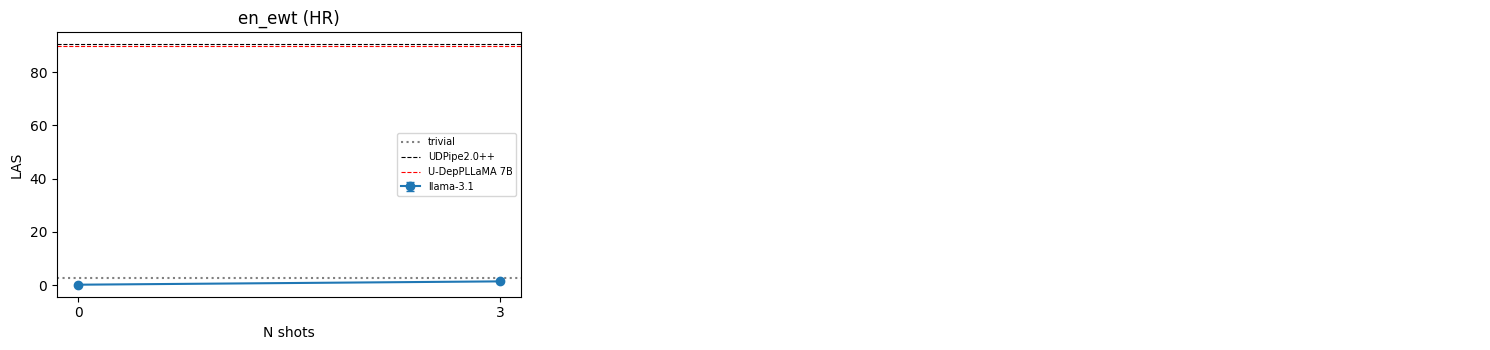

In [ ]:
tbs = sorted(df.treebank.unique()); ncol = 3; nrow = math.ceil(len(tbs) / ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(5 * ncol, 3.6 * nrow), squeeze=False)
for ax, tb in zip(axes.flat, tbs):
    for m, g in agg[agg.treebank == tb].groupby("model"):
        ax.errorbar(g.N, g.LAS, yerr=g.LAS_sd.fillna(0), marker="o", capsize=3, label=m)
    ax.axhline(TRIVIAL[tb]["LAS"], ls=":", c="gray", label="trivial")
    if tb in REF: ax.axhline(REF[tb][0], ls="--", c="k", lw=.8, label="UDPipe2.0++"); ax.axhline(REF[tb][1], ls="--", c="r", lw=.8, label="U-DepPLLaMA 7B")
    ax.set_title(f"{tb} ({LEVEL[tb]})"); ax.set_xlabel("N shots"); ax.set_ylabel("LAS"); ax.set_xticks(sorted(df.N.unique()))
axes.flat[0].legend(fontsize=7)
for ax in list(axes.flat)[len(tbs):]: ax.axis("off")
plt.tight_layout(); plt.savefig(f"{CFG['out_dir']}/las_vs_shots.png", dpi=150); plt.show()

In [ ]:
# Decision rule: weighted mean LAS over treebanks (LR languages weigh more), best N, and 0 -> max-shot slope
Nmax = agg.N.max()
best = agg[agg.N == Nmax].copy(); best["w"] = best.treebank.map(LEVEL).map(WEIGHT)
rank = (best.groupby("model").apply(lambda g: pd.Series({
            "wLAS@Nmax": np.average(g.LAS, weights=g.w), "wUAS@Nmax": np.average(g.UAS, weights=g.w),
            "invalid%": g.invalid.mean()})))
if 0 in agg.N.values:
    zero = agg[agg.N == 0].copy(); zero["w"] = zero.treebank.map(LEVEL).map(WEIGHT)
    z = zero.groupby("model").apply(lambda g: np.average(g.LAS, weights=g.w))
    rank["wLAS@0"] = z; rank["gain/shot"] = (rank["wLAS@Nmax"] - rank["wLAS@0"]) / Nmax
print(rank.sort_values("wLAS@Nmax", ascending=False).round(2))
print("\nCarry the top models forward to multilingual LoRA SFT. A steep gain/shot indicates latent syntactic ability.")

           wLAS@Nmax  wUAS@Nmax  invalid%  wLAS@0  gain/shot
model                                                       
llama-3.1       1.38       2.27      84.0    0.13       0.42

Carry the top models forward to multilingual LoRA SFT. A steep gain/shot indicates latent syntactic ability.


/tmp/ipykernel_306/2745050560.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  rank = (best.groupby("model").apply(lambda g: pd.Series({
/tmp/ipykernel_306/2745050560.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  z = zero.groupby("model").apply(lambda g: np.average(g.LAS, weights=g.w))


## Notes
- **Ablations**: set `CFG["demo_source"]` (e.g. `{"bar_maibaam": "de_gsd", "fo_oft": "fo_farpahc"}`) for cross-lingual/cross-domain demonstrations; `CFG["mode"]="raw"` for end-to-end input (the model must tokenize; alignment is by word-form match, so $F_1$ differs from $\mathrm{LAS}$).
- **Context**: `demos_used` in the table shows the mean number of demonstrations that fit. Subword fragmentation of Faroese/Armenian/Bavarian can force it below $N$; this is a result, not a bug.
- **Bolmo / Aya**: check model ids and `trust_remote_code` support; byte-level models may need a different `max_new_tokens` budget (`run_batch` scales it by the *token* length of the gold tree).
- Push this notebook and `fewshot_ud/` result JSONs to GitHub.